# 03 — Extension quantique : formulation QUBO et recuit simulé

## 1. Quelle partie du problème peut bénéficier de l'optimisation quantique ?

Trouver **un** chemin pour **un** agent est facile (A* est polynomial). Ce qui est difficile, c'est la **coordination** : choisir *simultanément* un chemin pour chaque agent de façon à éviter tous les conflits en minimisant le coût global. C'est un problème **combinatoire** : avec $N$ agents et $K$ chemins possibles par agent, il y a $K^N$ combinaisons.

C'est cette **sélection conjointe de chemins** que l'on formule en QUBO. A* reste classique : il sert à générer des chemins candidats. → schéma **hybride quantique-classique**, comme dans l'article de Gerlach et al. (ICML 2025).

## 2. Formulation QUBO

Variable binaire : $x_{i,k} = 1$ si l'agent $i$ suit son chemin candidat $k$.

$$
H(x) = \underbrace{\sum_{i,k} c_{i,k}\, x_{i,k}}_{\text{coût des chemins}}
\;+\; A \sum_i \Big(1 - \sum_k x_{i,k}\Big)^2_{\text{un seul chemin par agent}}
\;+\; B \sum_{(i,k),(j,l),\, i\neq j} n_{\text{conf}}(i,k;j,l)\, x_{i,k}\, x_{j,l}
$$

- $c_{i,k}$ : durée du chemin $k$ de l'agent $i$.
- $n_{\text{conf}}$ : nombre de conflits (sommet ou arête) entre deux chemins, calculé à l'avance.
- Les contraintes deviennent des **pénalités** : c'est ce qui rend le problème **non contraint**.

Comme $x^2 = x$, on a $A(1-\sum_k x_k)^2 = A - A\sum_k x_k + 2A\sum_{k<l}x_k x_l$ : tout s'écrit $\min_x x^\top Q x$, le format accepté par un recuit quantique (D-Wave) ou par QAOA.

**Choix des pénalités :** $A$ et $B$ doivent être plus grands que tout gain obtenu en violant une contrainte. On prend $A = B = \sum_i \max_k c_{i,k} + 1$.

In [1]:
import sys
sys.path.insert(0, "..")
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.environment import Grid, Agent, ScenarioGenerator
from src.coordinator import PrioritizedPlanner, detect_conflicts
from src.qubo_solver import (CandidatePathGenerator, MAPFQubo, SimulatedAnnealingSolver,
                             ExhaustiveSolver, QUBOPlanner)
from src.simulation import Simulation
from src.visualization import plot_paths

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 2)
FIG = "../results/"

## 3. Exemple pédagogique : deux drones qui se croisent

Grille 3×3 sans obstacle : l'agent 0 va de gauche à droite, l'agent 1 de haut en bas. Leurs chemins directs se rencontrent au centre à t = 1.

In [2]:
grid = Grid(3, 3)
agents = [Agent(0, (1, 0), (1, 2)), Agent(1, (0, 1), (2, 1))]
gen = CandidatePathGenerator(grid, n_candidates=3, max_delay=1)
goals = {a.goal for a in agents}
candidates = {a.agent_id: gen.generate(a.start, a.goal, avoid=goals) for a in agents}
for i, paths in candidates.items():
    for k, p in enumerate(paths):
        print(f"x[{i},{k}]  coût={len(p)-1}  {p}")

x[0,0]  coût=2  [(1, 0), (1, 1), (1, 2)]
x[0,1]  coût=3  [(1, 0), (1, 0), (1, 1), (1, 2)]
x[0,2]  coût=4  [(1, 0), (2, 0), (1, 0), (1, 1), (1, 2)]
x[1,0]  coût=2  [(0, 1), (1, 1), (2, 1)]
x[1,1]  coût=3  [(0, 1), (0, 1), (1, 1), (2, 1)]
x[1,2]  coût=4  [(0, 1), (1, 1), (2, 1), (2, 0), (2, 1)]


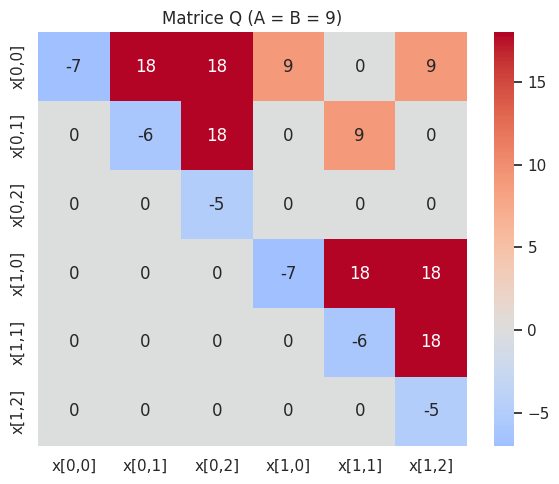

In [3]:
model = MAPFQubo(candidates)
labels = [f"x[{i},{k}]" for i, k in model.index]
plt.figure(figsize=(6, 5))
sns.heatmap(model.Q, annot=True, fmt=".0f", cmap="coolwarm", center=0,
            xticklabels=labels, yticklabels=labels)
plt.title(f"Matrice Q (A = B = {model.A:.0f})")
plt.tight_layout(); plt.savefig(FIG + "qubo_matrix_example.png", dpi=120); plt.show()

Lecture de Q : la **diagonale** = coût du chemin − A (négative, elle pousse à choisir un chemin) ; les termes **entre chemins d'un même agent** = +2A (interdit d'en choisir deux) ; les termes **entre agents** = B × nombre de conflits.

### Énergie de toutes les affectations possibles (2⁴ = 16)

In [4]:
rows = []
for bits in itertools.product([0, 1], repeat=model.n):
    x = np.array(bits)
    chosen, valid = model.decode(x)
    rows.append({"x": "".join(map(str, bits)), "énergie": model.energy(x), "one-hot valide": valid})
energies = pd.DataFrame(rows).sort_values("énergie")
energies.head(6)

,x,énergie,one-hot valide
20,010100,5.0,True
34,100010,5.0,True
12,001100,6.0,True
17,010001,7.0,True
10,001010,7.0,True
9,001001,8.0,True


Recuit simulé : 100010 | énergie = 5.0 | valide = True
Conflits : []


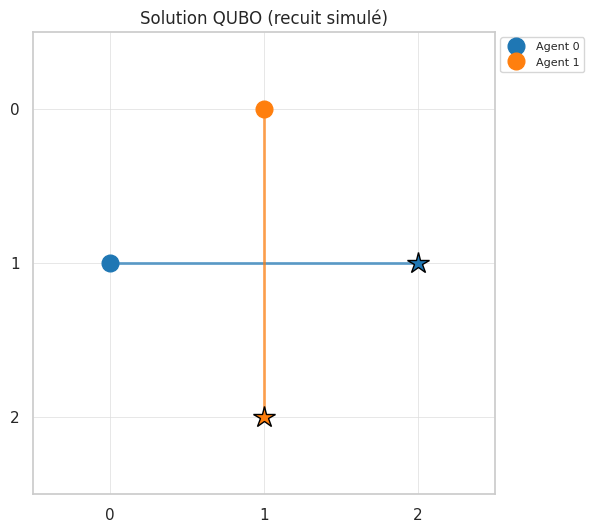

In [5]:
x_sa = SimulatedAnnealingSolver(seed=0).solve(model.Q)
chosen, valid = model.decode(x_sa)
print("Recuit simulé :", "".join(map(str, x_sa)), "| énergie =", model.energy(x_sa), "| valide =", valid)
for a in agents:
    a.path = chosen[a.agent_id]
print("Conflits :", detect_conflicts(agents))
plot_paths(grid, agents, title="Solution QUBO (recuit simulé)"); plt.show()

Le minimum d'énergie correspond à une affectation **valide et sans conflit** : un des deux agents attend un pas. Le recuit simulé retrouve ce minimum.

## 4. Le recuit simulé, version « quantum-inspired »

| Recuit simulé (classique) | Recuit quantique (D-Wave) |
|---|---|
| Fluctuations **thermiques** : on accepte une mauvaise solution avec probabilité $e^{-\Delta E / T}$ | Fluctuations **quantiques** : effet tunnel à travers les barrières d'énergie |
| La température $T$ décroît lentement | Le champ transverse décroît lentement |
| Même entrée : la matrice $Q$ | Même entrée : la matrice $Q$ |

Le même modèle $Q$ pourrait donc être envoyé tel quel à un recuit quantique (par ex. via `dimod` / D-Wave Ocean) : seul le solveur change.

## 5. Comparaison avec l'approche classique (scénarios 1 et 2, 20 instances chacun)

In [6]:
STRATEGIES = [("A* prioritaire (classique)", PrioritizedPlanner, {}),
              ("QUBO + recuit simulé", QUBOPlanner, {}),
              ("QUBO + exact (référence)", QUBOPlanner, {"solver": "exact"})]
rows = []
for n in [2, 5]:
    for seed in range(20):
        grid, agents = ScenarioGenerator(10, 10, 0.15, seed=seed).generate(n)
        for name, P, kw in STRATEGIES:
            sim = Simulation(grid, agents, P, **kw)
            m = sim.run()
            rows.append({**m.to_dict(), "planner": name, "seed": seed,
                         "scenario": f"{n} agents",
                         "valid": getattr(sim.planner, "valid", True)})
qdf = pd.DataFrame(rows)
qdf.to_csv(FIG + "quantum_comparison.csv", index=False)
summary = qdf.groupby(["scenario", "planner"]).agg(
    conflits=("n_conflicts", "mean"), succes_pct=("success_rate", "mean"),
    affectation_valide_pct=("valid", lambda s: 100 * s.mean()),
    sum_of_costs=("sum_of_costs", "mean"), makespan=("makespan", "mean"),
    runtime_ms=("runtime_ms", "mean"))
summary

conflits  succes_pct  \
scenario planner                                            
2 agents A* prioritaire (classique)       0.0       100.0   
         QUBO + exact (référence)         0.0       100.0   
         QUBO + recuit simulé             0.0       100.0   
5 agents A* prioritaire (classique)       0.0       100.0   
         QUBO + exact (référence)         0.0       100.0   
         QUBO + recuit simulé             0.0       100.0   

                                     affectation_valide_pct  sum_of_costs  \
scenario planner                                                            
2 agents A* prioritaire (classique)                   100.0         15.25   
         QUBO + exact (référence)                     100.0         14.85   
         QUBO + recuit simulé                         100.0         15.15   
5 agents A* prioritaire (classique)                   100.0         38.55   
         QUBO + exact (référence)                     100.0         36.75   
         QUBO + recuit simulé                         100.0         39.05   

                                     makespan  runtime_ms  
scenario planner                                           
2 agents A* prioritaire (classique)      9.35        0.30  
         QUBO + exact (référence)        9.45        2.86  
         QUBO + recuit simulé            9.55       39.53  
5 agents A* prioritaire (classique)     11.45        0.65  
         QUBO + exact (référence)       11.90       35.49  
         QUBO + recuit simulé           12.30       92.65

Pour le planificateur prioritaire, `nodes_expanded` = nœuds A* explorés ; pour le QUBO, c'est le **nombre de variables binaires**, c'est-à-dire le nombre de **qubits** qu'il faudrait sur un recuit quantique.

In [7]:
qdf[qdf.planner != "A* prioritaire (classique)"].groupby("scenario").nodes_expanded.mean().rename("variables (qubits)")

scenario
2 agents    12.00
5 agents    29.75
Name: variables (qubits), dtype: float64

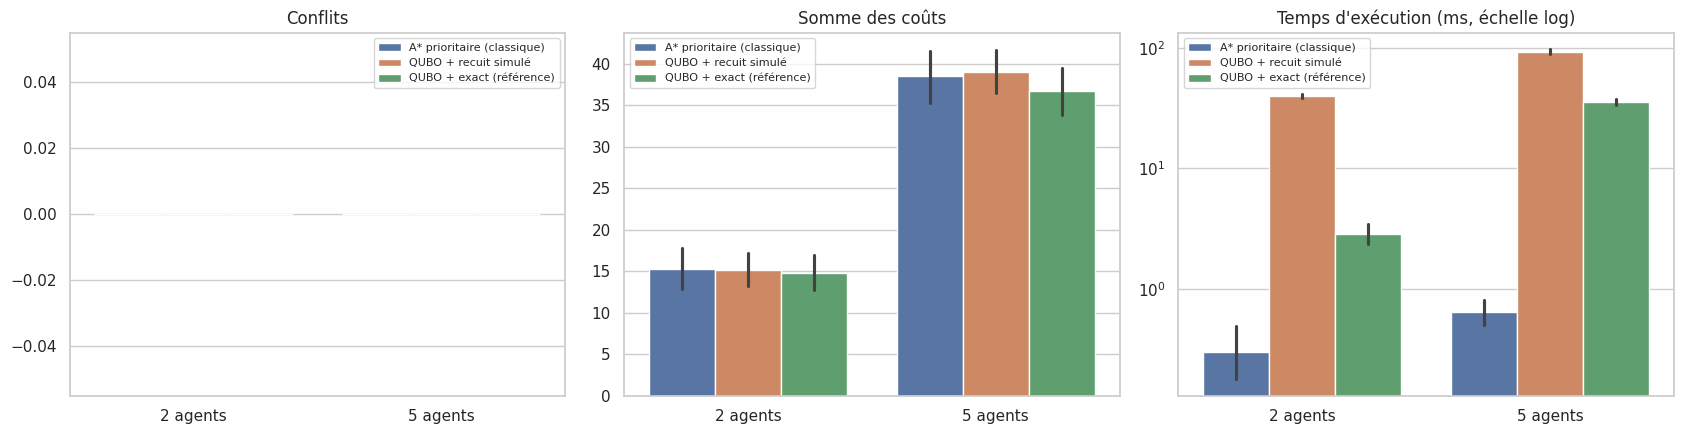

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (metric, label) in zip(axes, [("n_conflicts", "Conflits"), ("sum_of_costs", "Somme des coûts"),
                                      ("runtime_ms", "Temps d'exécution (ms, échelle log)")]):
    sns.barplot(data=qdf, x="scenario", y=metric, hue="planner", ax=ax)
    ax.set_title(label); ax.set_xlabel(""); ax.set_ylabel(""); ax.legend(fontsize=8)
axes[2].set_yscale("log")
plt.tight_layout(); plt.savefig(FIG + "quantum_comparison.png", dpi=120); plt.show()

## 6. Sensibilité aux pénalités

Le réglage de $A$ et $B$ est la principale difficulté pratique d'un QUBO. On multiplie les pénalités par un facteur λ (scénario 2, 20 instances).

In [9]:
rows = []
for lam in [0.1, 0.25, 0.5, 1.0, 2.0]:
    for seed in range(20):
        grid, agents = ScenarioGenerator(10, 10, 0.15, seed=seed).generate(5)
        gen = CandidatePathGenerator(grid)
        goals = {a.goal for a in agents}
        cands = {a.agent_id: gen.generate(a.start, a.goal, avoid=goals) for a in agents}
        base = MAPFQubo(cands)
        model = MAPFQubo(cands, penalty_onehot=lam * base.A, penalty_conflict=lam * base.B)
        chosen, valid = model.decode(SimulatedAnnealingSolver(seed=0).solve(model.Q))
        sol = [Agent(i, p[0], p[-1], p) for i, p in chosen.items()]
        rows.append({"lambda": lam, "valide": valid, "conflits": len(detect_conflicts(sol)),
                     "sum_of_costs": sum(len(p) - 1 for p in chosen.values())})
sens = pd.DataFrame(rows).groupby("lambda").mean()
sens["valide"] *= 100
sens.rename(columns={"valide": "affectation_valide_%"})

,affectation_valide_%,conflits,sum_of_costs
lambda,,,
0.10,0.0,1.90,35.50
0.25,95.0,0.05,37.60
0.50,100.0,0.00,39.10
1.00,100.0,0.00,39.05
2.00,100.0,0.00,39.30


Lecture : des pénalités **trop faibles** laissent le solveur violer les contraintes (agents sans chemin, ou conflits acceptés car « moins chers »). Des pénalités **trop fortes** rendent le paysage d'énergie très accidenté et le recuit a plus de mal à trouver l'optimum. Il faut donc un compromis.

## 7. Taille du problème

In [10]:
K = 6
size = pd.DataFrame({"agents N": [2, 5, 10, 20, 50]})
size["variables N·K"] = size["agents N"] * K
size["termes quadratiques max"] = size["variables N·K"] * (size["variables N·K"] - 1) // 2
size["combinaisons K^N"] = [f"{K**n:.2e}" for n in size["agents N"]]
size

,agents N,variables N·K,termes quadratiques max,combinaisons K^N
0,2,12,66,3.60e+01
1,5,30,435,7.78e+03
2,10,60,1770,6.05e+07
3,20,120,7140,3.66e+15
4,50,300,44850,8.08e+38


Le nombre de qubits croît **linéairement** ($N \cdot K$) mais l'espace de recherche croît **exponentiellement** ($K^N$) : c'est précisément le régime où un solveur heuristique (recuit simulé ou quantique) est pertinent, alors que l'énumération exacte devient impossible.

## 8. Avantages et limites d'une approche quantique

*Brouillon à reformuler avec tes propres mots.*

**Avantages potentiels**
- Optimisation **globale** et **simultanée** : tous les agents sont décidés ensemble, sans ordre de priorité arbitraire (contrairement à la planification prioritaire, incomplète).
- Formulation générique : ajouter un critère (énergie, batterie, zones interdites) = ajouter des termes dans $Q$.
- Le recuit quantique peut explorer le paysage d'énergie par effet tunnel et échantillonner plusieurs bonnes solutions rapidement.

**Limites**
- **Qualité des candidats** : le QUBO ne peut choisir que parmi les chemins fournis. Sans le candidat qui « contourne la cible d'un autre agent », certaines instances n'avaient aucune combinaison sans conflit. L'article traite ce point avec une génération itérative de candidats (*column generation*).
- **Réglage des pénalités** A et B (section 6).
- **Matériel actuel (NISQ)** : peu de qubits, connectivité limitée (embedding), bruit ; aucun avantage quantique démontré à ce jour pour ce type de problème.
- **Temps de calcul** : ici, le planificateur prioritaire reste bien plus rapide ; le QUBO est surtout intéressant pour la **qualité globale** des solutions sur des instances denses.
- Le recuit simulé donne une solution **approchée** : légèrement plus coûteuse que l'optimum exact.